# 2. Glyph substitution

textsynth can patch the font in memory before it draws the text. Jawi has the
pair `مم`, which Arabic and Persian do not have. `GlyphSubstitution` draws the
pair as one glyph.

This notebook uses Scheherazade New and not Amiri. Amiri draws four different
medial mims and selects one of them by the letter before. Scheherazade New
draws one mim, and each change below comes from the patch.

In [ ]:
from textsynth import (
    BorrowedGlyph,
    CompositeGlyph,
    Font,
    GlyphSubstitution,
    Layout,
    Synthesizer,
    shaped_sequences,
)
from nbutil import DONOR, PLAIN, columns

TEXT = "سايا ممباچ سورت خبر"

textsynth shapes the pair in the four joining contexts. The glyphs that come
out become the inputs of the rule.

`GlyphSubstitution` injects the outline as a real glyph. Then it adds a GSUB
lookup that maps the runs to the new glyph. The lookup goes last, after the
font's own lookups.

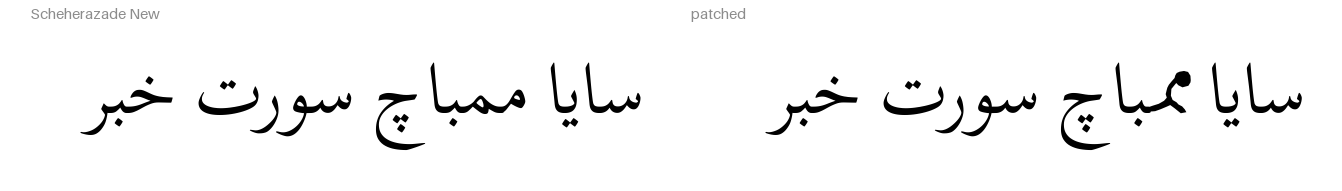

In [3]:
mim = GlyphSubstitution("مم", BorrowedGlyph(DONOR, "A"))
layout = Layout(size=72, tracking=-1, supersample=2)

before = Synthesizer(font=PLAIN, layout=layout)(TEXT)
after = Synthesizer(font=PLAIN, layout=layout, font_patches=[mim])(TEXT)
columns([("", before, after)], headings=("Scheherazade New", "patched"), gutter=20)

`patch_font` gives a new `Font` that holds new bytes. The file on disk does
not change.

A substitution can apply to some contexts only. It can also use a different
outline in each context.

The new outline can come from the font itself. This example takes the font's
own mim two times, and puts one below the other with `CompositeGlyph`. The
result keeps the weight and the pen angle of the face. A glyph from a donor
font does not.

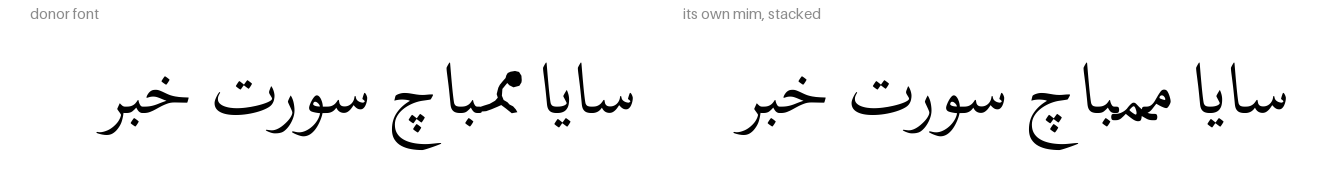

In [6]:
names = Font(PLAIN).glyph_order
pair = shaped_sequences(PLAIN, "مم", contexts=("initial", "medial"))

stacked = {
    # CompositeGlyph lays its parts out left to right, thus for Arabic the
    # letter you read first goes last.
    context: CompositeGlyph(
        [BorrowedGlyph(PLAIN, names[second], dy=-0.10), BorrowedGlyph(PLAIN, names[first])],
        overlap=0.12,
    )
    for context, (first, second) in pair.items()
}

borrowed = Synthesizer(font=PLAIN, layout=layout, font_patches=[GlyphSubstitution("مم", BorrowedGlyph(DONOR, "A"))])(
    TEXT
)
composed = Synthesizer(
    font=PLAIN, layout=layout, font_patches=[GlyphSubstitution("مم", stacked, contexts=tuple(pair))]
)(TEXT)
columns([("", borrowed, composed)], headings=("donor font", "its own mim, stacked"), gutter=20)